### Порівняння послідовного крускала та фільтр-крускала

In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv('C:/Users/admin/source/repos/Kruskal/results/seq_comparison_final.csv')
# df2 = pd.read_csv('C:/Users/admin/source/repos/Kruskal/results/fk.csv')

In [3]:
w1 = df.groupby('graph')['total_weight'].first()
info = df.groupby("graph", sort=False)[["family", "V", "E"]].first()     # сімейство і розмір кожного графа
order = list(df["graph"].unique())                                       # порядок графів як у плані
# w2 = df2.groupby('graph')['total_weight'].first()
# assert (w1 == w2.reindex(w1.index)).all(), "файли з різних графів!"

In [4]:
grouped = df[df["algorithm"]=="kruskal"].groupby(['graph'], sort=False)[['total_ms', 'sort_ms', 'dsu_ms']].mean().reindex(order)
grouped['sort_pct'] = (grouped['sort_ms'] / grouped['total_ms']) * 100
grouped['dsu_pct'] = (grouped['dsu_ms'] / grouped['total_ms']) * 100
grouped['інше_ms'] = grouped['total_ms'] - grouped['sort_ms'] - grouped['dsu_ms']

grouped2 = df[df["algorithm"]=="fk"].groupby(['graph'], sort=False)[['E', 'total_ms', 'sorted_edges']].mean().reindex(order)
grouped2['sorted_pct'] = 100 * (grouped2['sorted_edges'] / grouped2['E'])

In [5]:
seq_df = grouped.copy()
seq_df = seq_df[['total_ms', 'sort_ms', 'dsu_ms', 'інше_ms', 'sort_pct', 'dsu_pct']]
seq_df.insert(0, "E", info["E"])
seq_df.insert(0, "V", info["V"])

seq_df2 = grouped2[['total_ms', 'sorted_edges', 'sorted_pct']].copy()
seq_df2.insert(0, "E", info["E"])
seq_df2.insert(0, "V", info["V"])

In [6]:
display(seq_df.round(2))

,V,E,total_ms,sort_ms,dsu_ms,інше_ms,sort_pct,dsu_pct
graph,,,,,,,,
B1,8000,16000,1.14,0.87,0.22,0.05,75.95,19.29
B2,8000,32000,2.25,1.87,0.27,0.11,83.01,12.08
B3,8000,64000,4.28,3.78,0.29,0.21,88.25,6.84
B4,8000,128000,8.54,7.99,0.26,0.29,93.55,3.06
B5,8000,256000,17.40,16.61,0.26,0.53,95.45,1.49
B6,8000,512000,35.20,33.76,0.29,1.14,95.93,0.82
B7,8000,1024000,71.06,68.57,0.29,2.20,96.49,0.41
B8,8000,2048000,137.82,133.29,0.29,4.23,96.71,0.21
B9,8000,4096000,269.03,260.36,0.28,8.39,96.78,0.10


In [7]:
seq_df.to_excel('C:/Users/admin/source/repos/Kruskal/results/seq_kruskal_metrics.xlsx')

In [8]:
display(seq_df2.round(2))

,V,E,total_ms,sorted_edges,sorted_pct
graph,,,,,
B1,8000,16000,0.90,11449.0,71.56
B2,8000,32000,1.10,11442.0,35.76
B3,8000,64000,1.54,11337.0,17.71
B4,8000,128000,2.25,11788.0,9.21
B5,8000,256000,3.43,11641.0,4.55
B6,8000,512000,6.68,11305.0,2.21
B7,8000,1024000,11.90,11422.0,1.12
B8,8000,2048000,24.08,11149.0,0.54
B9,8000,4096000,44.68,11585.0,0.28


In [9]:
cmp = seq_df.merge(seq_df2, on=['graph'], suffixes=('_kruskal', '_fk'))
cmp['fk_speedup'] = cmp['total_ms_kruskal'] / cmp['total_ms_fk']

In [10]:
table = cmp.merge(df.groupby('graph', sort=False)[['V', 'E']].first().reset_index(), on='graph')

report = pd.DataFrame({
    ('Граф', ''):                          table['graph'],
    ('Граф', 'V'):                         table['V'],
    ('Граф', 'E'):                         table['E'],
    ('Час виконання, мс', 'Крускал'):        table['total_ms_kruskal'].round(2),
    ('Час виконання, мс', 'Filter-Kruskal'): table['total_ms_fk'].round(2),
    ('FK швидший, разів', ''):             table['fk_speedup'].round(2),
    ('Відсортовано ребер у FK', 'кількість'): table['sorted_edges'].astype(int),
    ('Відсортовано ребер у FK', '%'):         table['sorted_pct'].round(2),
})
report.columns = pd.MultiIndex.from_tuples(report.columns)
display(report.style.hide(axis='index'))

report.to_excel('C:/Users/admin/source/repos/Kruskal/results/seq_comparison6.xlsx')

In [11]:
phases = grouped.merge(df.groupby('graph', sort=False)[['V', 'E']].first().reset_index(), on='graph')
phases['інше_ms'] = phases['total_ms'] - phases['sort_ms'] - phases['dsu_ms']

def pct(col):
    return (100 * phases[col] / phases['total_ms'])

kruskal_phases = pd.DataFrame({
    ('Граф', ''):                            phases['graph'],
    ('Граф', 'V'):                           phases['V'],
    ('Граф', 'E'):                           phases['E'],
    ('Загальний час, мс', ''):               phases['total_ms'].round(2),
    ('Сортування', 'мс'):                    phases['sort_ms'].round(2),
    ('Сортування', '%'):                     pct('sort_ms'),
    ('Прохід DSU', 'мс'):                    phases['dsu_ms'].round(2),
    ('Прохід DSU', '%'):                     pct('dsu_ms'),
    ('Копіювання та звільнення пам\'яті', 'мс'): phases['інше_ms'].round(2),
    ('Копіювання та звільнення пам\'яті', '%'):  pct('інше_ms'),
})
kruskal_phases.columns = pd.MultiIndex.from_tuples(kruskal_phases.columns)
pct_cols  = [c for c in kruskal_phases.columns if c[1] == '%']
ms_cols   = [c for c in kruskal_phases.columns if c[1] == 'мс' or c[0] == 'Загальний час, мс']

display(kruskal_phases.style
        .format('{:.2f}', subset=ms_cols)
        .format('{:.2f}', subset=pct_cols)
        .hide(axis='index'))

kruskal_phases.to_excel('C:/Users/admin/source/repos/Kruskal/results/kruskal_phases.xlsx')

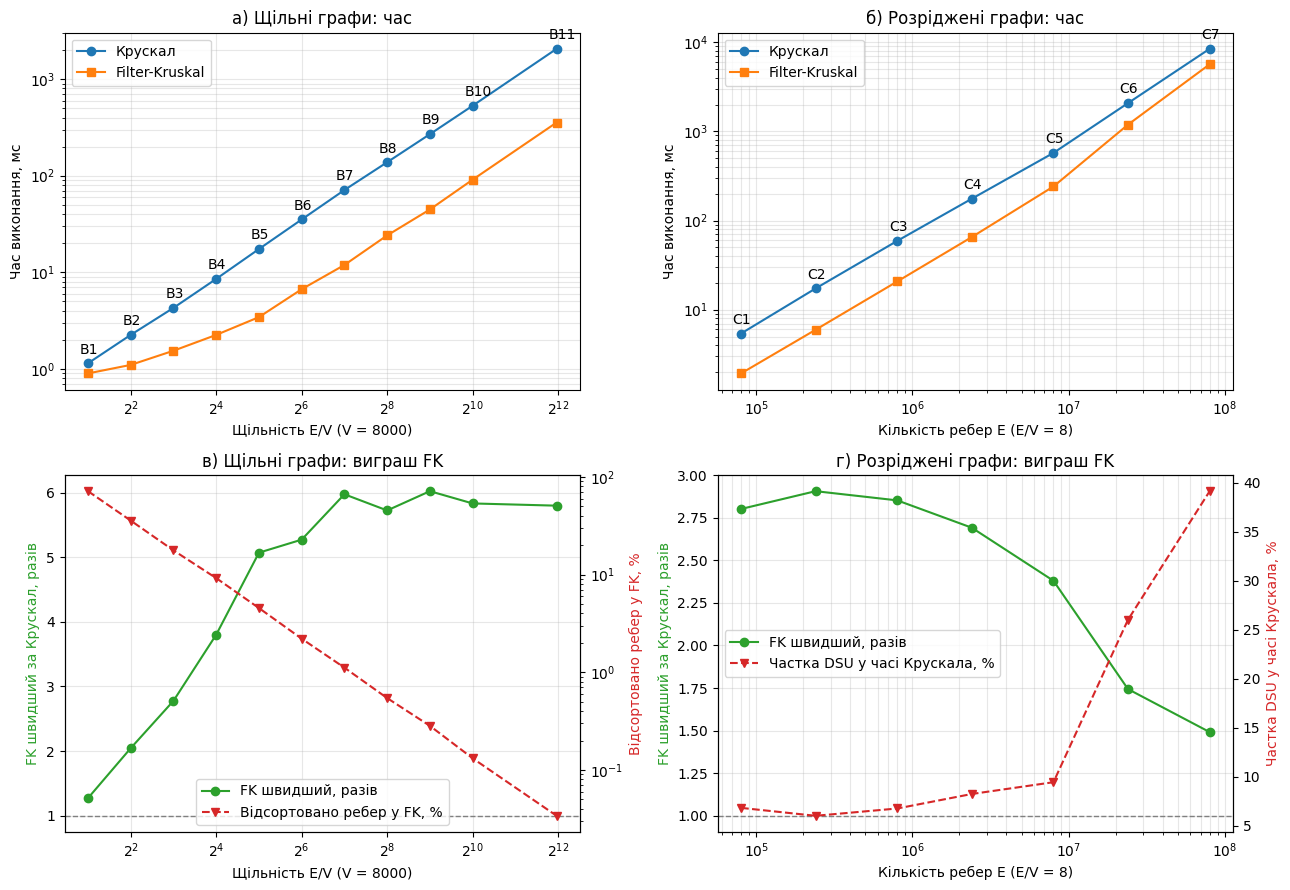

In [12]:
import matplotlib.pyplot as plt

table['family'] = table['graph'].map(info['family'])

dense  = table[table['family'] == 'dense']
sparse = table[table['family'] == 'sparse']

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
x_dense = dense['E'] / dense['V']


def time_plot(ax, x, data, xlabel, title, base):
    ax.plot(x, data['total_ms_kruskal'], 'o-', label='Крускал')
    ax.plot(x, data['total_ms_fk'], 's-', label='Filter-Kruskal')

    # Підписи назв графів над точками Крускала
    for xi, yi, name in zip(x, data['total_ms_kruskal'], data['graph']):
        ax.annotate(name, (xi, yi), textcoords='offset points', xytext=(-6, 7), fontsize=10)

    ax.set_xscale('log', base=base); ax.set_yscale('log')
    ax.set_xlabel(xlabel); ax.set_ylabel('Час виконання, мс')
    ax.set_title(title)
    ax.grid(True, which='both', alpha=0.3); ax.legend()


def ratio_plot(ax, x, data, second, second_label, xlabel, title, base, second_log, legend_loc):
    ax.plot(x, data['fk_speedup'], 'o-', color='tab:green', label='FK швидший, разів')
    ax.axhline(1, color='gray', lw=1, ls='--')
    ax.set_xscale('log', base=base)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('FK швидший за Крускал, разів', color='tab:green')
    ax.set_title(title)
    ax.grid(True, which='both', alpha=0.3)
    ax2 = ax.twinx()
    ax2.plot(x, second, 'v--', color='tab:red', label=second_label)
    if second_log:
        ax2.set_yscale('log')
    ax2.set_ylabel(second_label, color='tab:red')
    lines = ax.get_lines()[:1] + ax2.get_lines()
    ax.legend(lines, [l.get_label() for l in lines], loc=legend_loc)


# а) б) Час виконання
time_plot(axes[0, 0], x_dense, dense, 'Щільність E/V (V = 8000)', 'а) Щільні графи: час', 2)
time_plot(axes[0, 1], sparse['E'], sparse, 'Кількість ребер E (E/V = 8)', 'б) Розріджені графи: час', 10)

# в) Щільні: виграш пояснюється часткою відсортованих ребер
ratio_plot(axes[1, 0], x_dense, dense, dense['sorted_pct'], 'Відсортовано ребер у FK, %',
           'Щільність E/V (V = 8000)', 'в) Щільні графи: виграш FK', 2, second_log=True,
           legend_loc='lower center')

# г) Розріджені: частка відсортованих майже стала, виграш падає через зростання частки DSU
dsu_share = 100 * sparse['dsu_ms'] / sparse['total_ms_kruskal']
ratio_plot(axes[1, 1], sparse['E'], sparse, dsu_share, 'Частка DSU у часі Крускала, %',
           'Кількість ребер E (E/V = 8)', 'г) Розріджені графи: виграш FK', 10, second_log=False,
           legend_loc='center left')

fig.tight_layout()
fig.savefig('C:/Users/admin/source/repos/Kruskal/results/seq_comparison.png', dpi=200)
plt.show()